# Hierarchical empirical convergence in Wasserstein-over-Wasserstein space

**Reference framework:** Bonet, Vauthier & Korba, *Flowing Datasets with Wasserstein over Wasserstein Gradient Flows* (ICML 2025): [paper](https://proceedings.mlr.press/v267/bonet25a.html) · [official implementation](https://github.com/clbonet/Flowing_Datasets_with_WoW_Gradient_Flows) · [rings experiment](https://github.com/clbonet/Flowing_Datasets_with_WoW_Gradient_Flows/blob/main/MMD%20-%20SW%20based%20Kernel%20-%20Rings.ipynb).

For class-conditional laws $\mu_c$, the empirical class measure and hierarchical dataset representation are

$$
\widehat\mu_{c,n}=\frac1n\sum_{i=1}^n\delta_{x_i^c},\qquad
\widehat P_{C,n}=\frac1C\sum_{c=1}^C\delta_{\widehat\mu_{c,n}}.
$$

In this notebook we run two synthetic experiments:

1. **Fixed $C=3$:** increase $n$ and compute the WoW distance to the true finite hierarchy $P_C$.
2. **Growing $C$ and $n$:** draw class laws independently from a known population law $\mathbb P$, then compute the WoW distance to that true $\mathbb P$. A fixed-$n$ control separates inner sampling error from outer class-sampling error.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import make_config, describe
import utils as U

# ---- Parameters -------------------
# Defaults live in config.py
OVERRIDES = {}
cfg = make_config(**OVERRIDES)
describe(cfg)

U.apply_style()
print("OT backend:", U.ot_backend())

Using config.py defaults.
OT backend: POT available; SciPy assignment used for equal-weight square problems


In [2]:
ring = U.build_ring(cfg)
print(f"Ring class laws: {len(cfg.fixed_c_centres)}; support atoms per class law: {ring.size}")
print('Base-ring mean:', ring.mean)

Ring class laws: 3; support atoms per class law: 2048
Base-ring mean: [4.44522891e-18 9.56351019e-17]


---
## Ring distributions

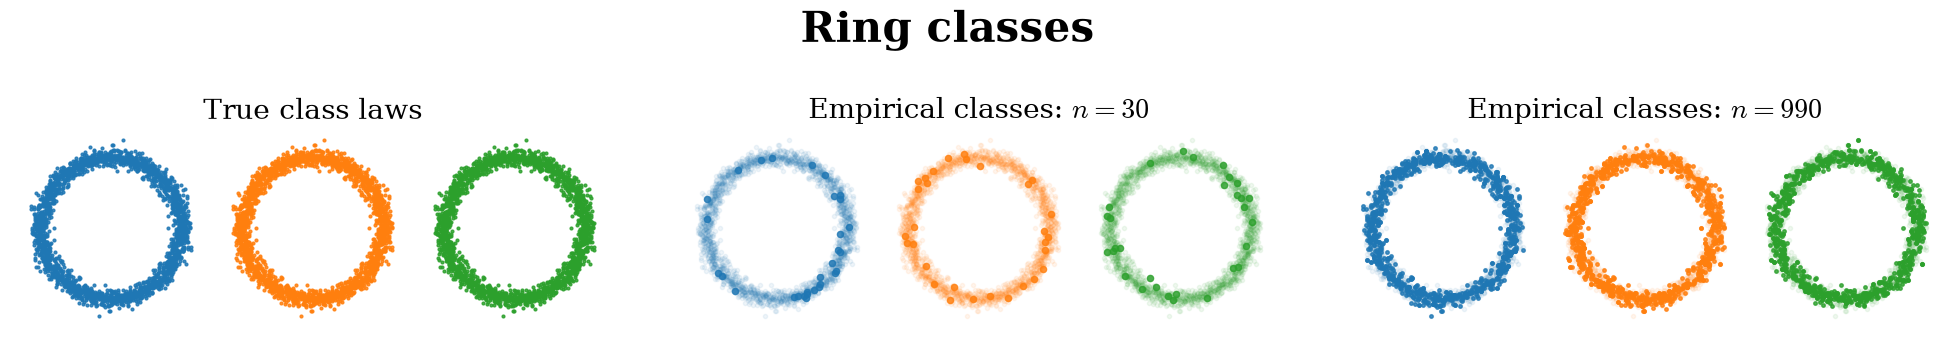

In [3]:
fig = U.plot_ring_schematic(cfg, ring)
plt.show()

---

## Experiment 1 — fixed class count C

In [4]:
df_fixed = U.run_fixed_c(cfg, ring)
U.save_convergence(cfg, df_fixed)
U.summarise_fixed_c(df_fixed).head(10)

Fixed-C convergence: 100%|██████████| 100/100 [06:22<00:00,  3.83s/it]


Saved 2560 rows to results/convergence/convergence.csv


,mean,std,count,ci_95
n_per_class,,,,
10,0.400747,0.060821,16,0.029802
20,0.278024,0.045986,16,0.022533
30,0.234745,0.032704,16,0.016025
40,0.198617,0.026547,16,0.013008
50,0.170745,0.025012,16,0.012256
60,0.173470,0.027028,16,0.013244
70,0.159498,0.028484,16,0.013957
80,0.157977,0.025159,16,0.012328
90,0.133473,0.020324,16,0.009959


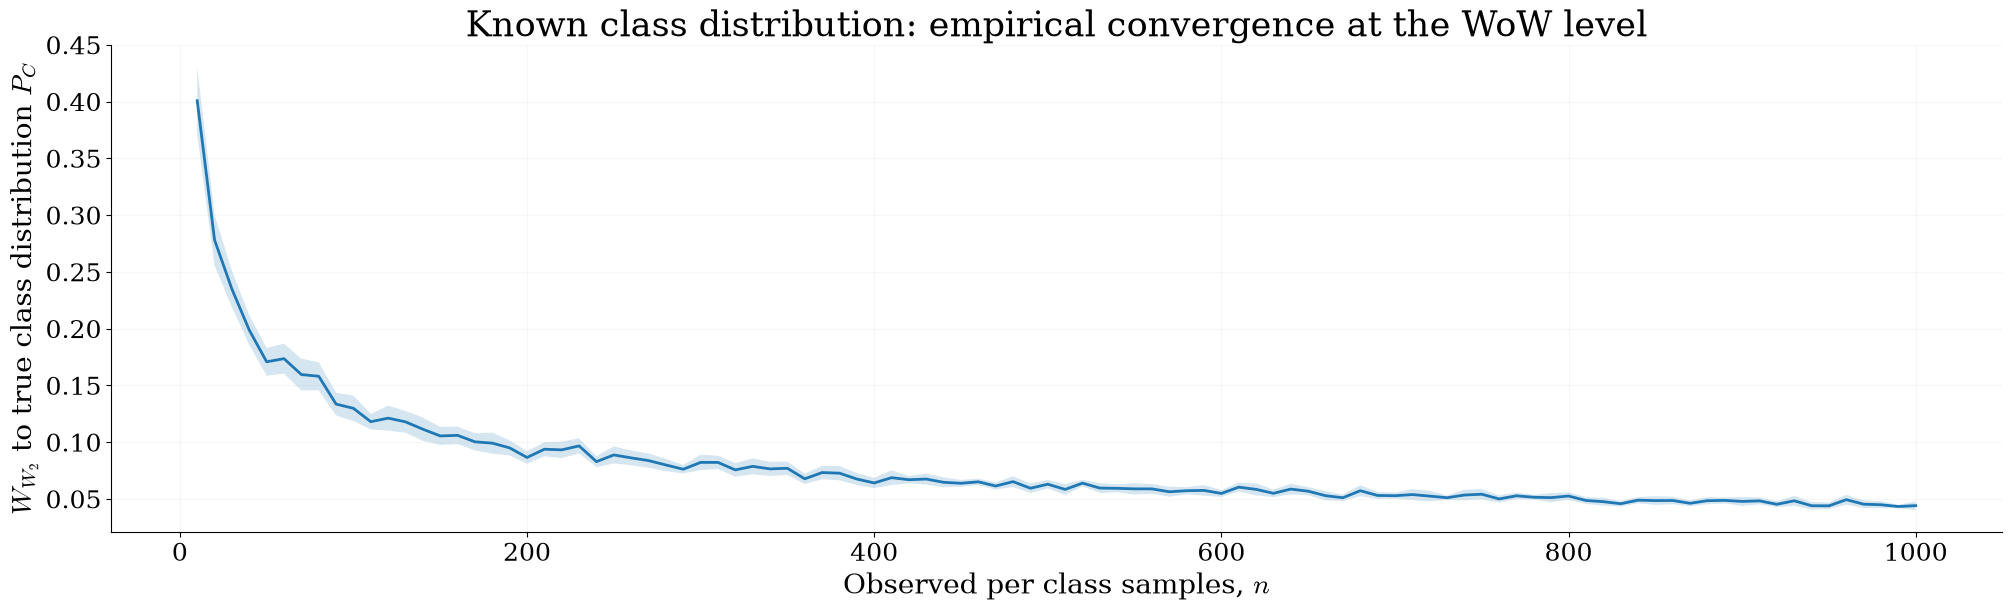

In [5]:
U.plot_fixed_c(df_fixed)
plt.show()

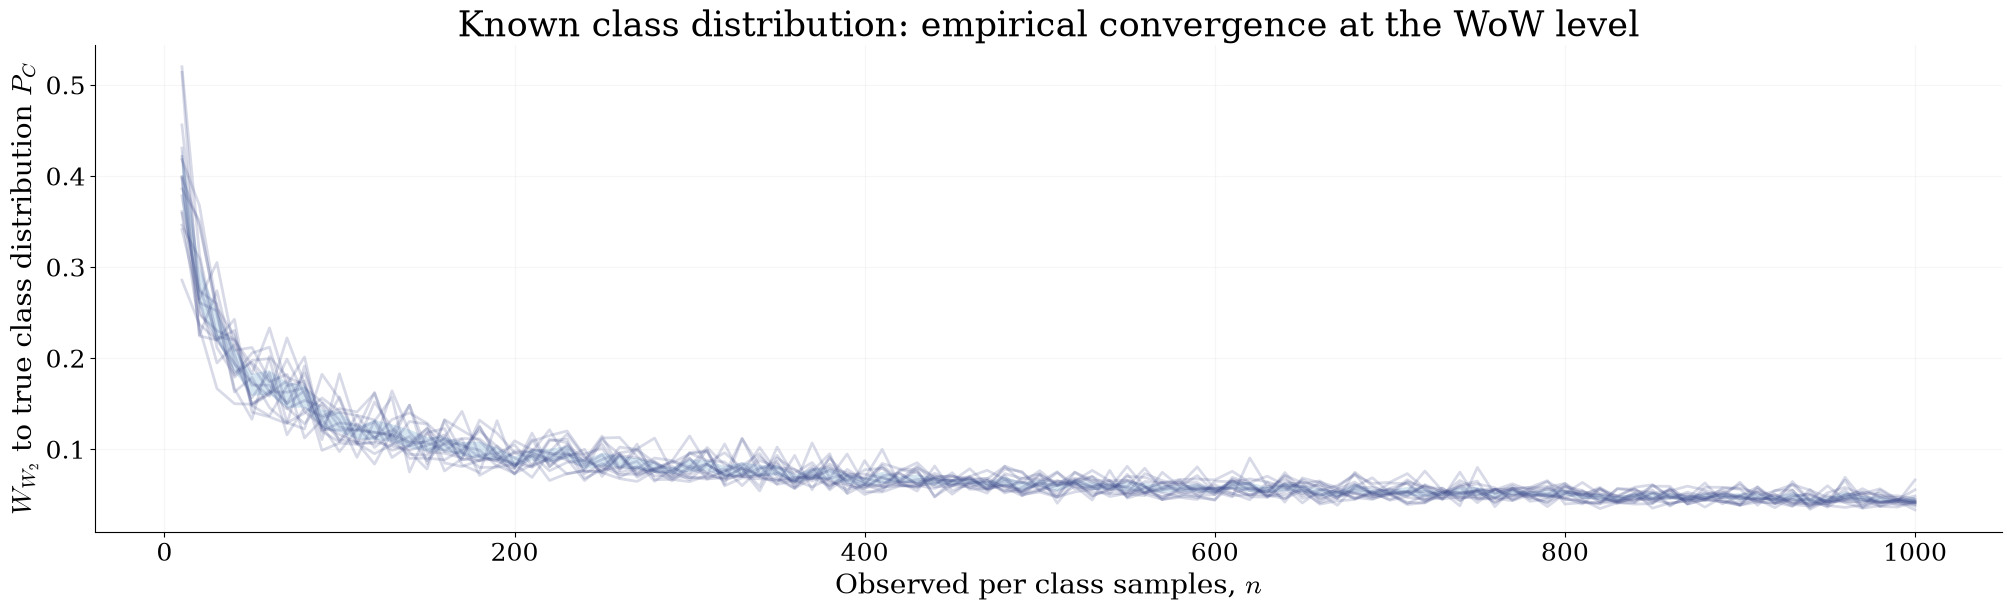

In [6]:
U.plot_fixed_c(df_fixed, individual=True)
plt.show()

---
## Experiment 2 — growing $C$: continuous population of ring laws

Each latent class distribution is a translated copy of the same ring measure, $\mu_a=(T_a)_\#\nu$, with centre $a$. The class population is

$$
\mathbb P=(a\mapsto\mu_a)_\#\operatorname{Unif}([-L,L]),\qquad L=\texttt{centre\_limit}.
$$

Class centres are sampled i.i.d. from this population and the within-class empirical measures are sampled from their corresponding ring laws. The **joint-growth** curve increases both $C$ and $n$, while the control increases $C$ at fixed $n$.

The joint-growth curve is the controlled analogue of the hierarchical sampling scheme: both the number of sampled class laws and the number of observations within each class increase.

In [7]:
df_growing = U.run_growing_c(cfg, ring)
U.save_convergence(cfg, df_growing)

Growing-C convergence: 100%|██████████| 20/20 [21:42<00:00, 65.13s/it] 

Saved 2560 rows to results/convergence/convergence.csv


PosixPath('results/convergence/convergence.csv')

### Reading the growing-$C$ figure

The solid curve increases both the number of latent class laws and within-class observations; the dashed control increases only the number of class laws while holding $n$ fixed. The centre-only panel isolates sampling of latent class locations. These are distances to the known population used in this synthetic construction.

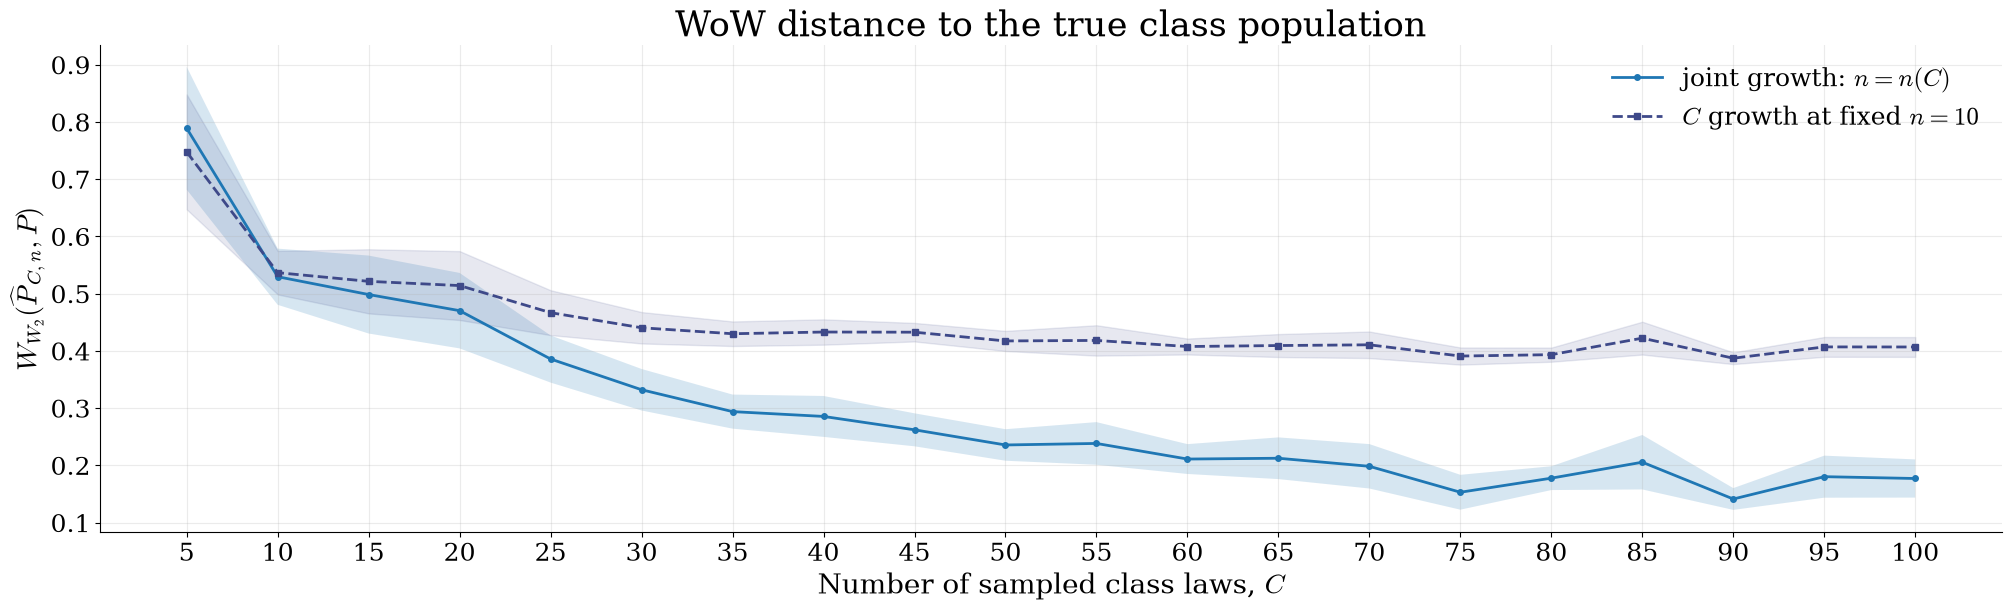

In [8]:
U.plot_growing_c(df_growing)
plt.show()

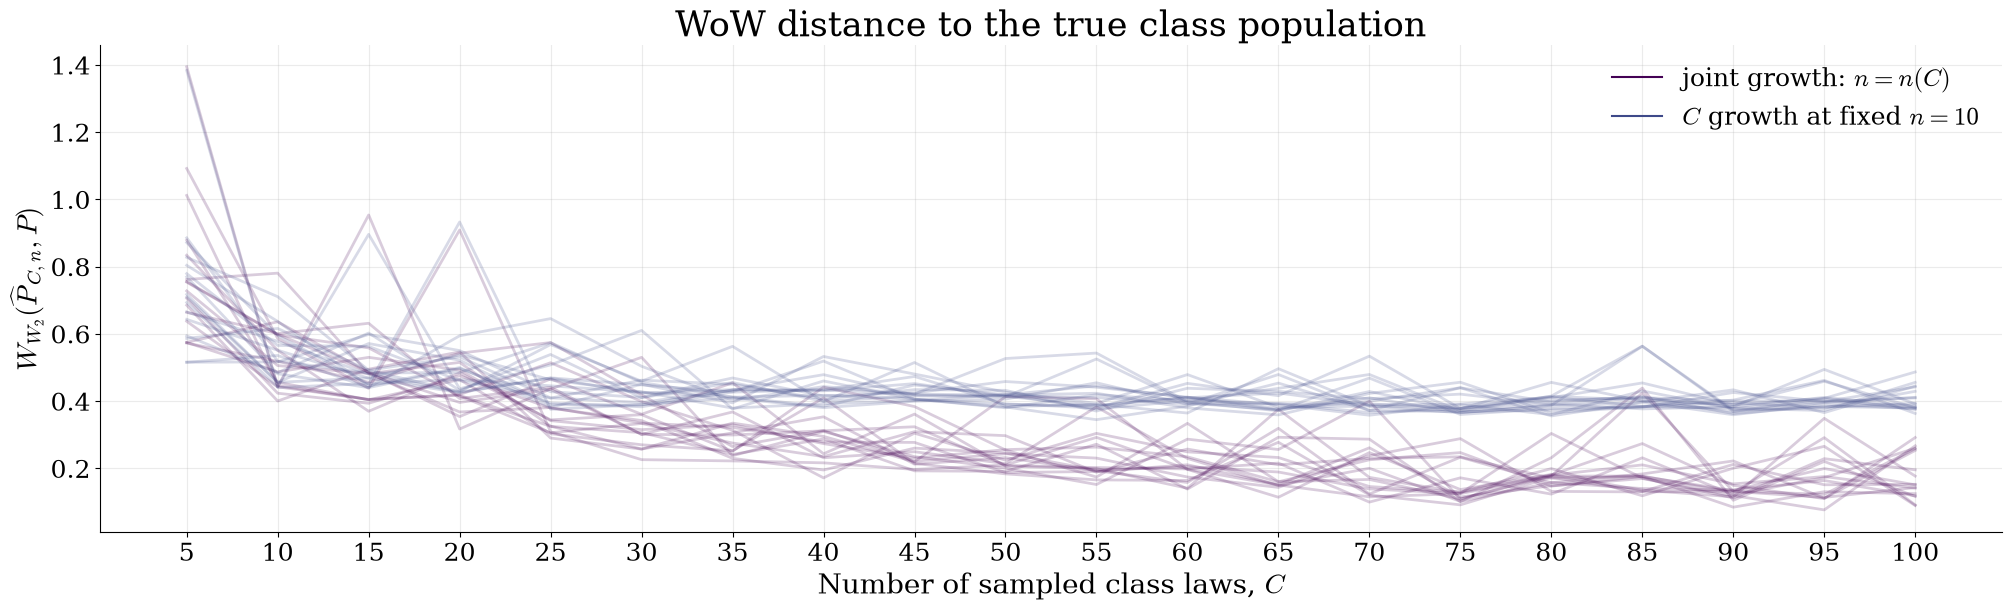

In [9]:
U.plot_growing_c(df_growing, individual=True)
plt.show()